In [1]:
import sys
sys.path.append('../..')
import numpy as np
from algorithm.SymANLS_pivot import SymANLS_pivot
import matplotlib.pyplot as plt

In [3]:
import sys
sys.path.append('../..')
from algorithm.SymANLS_pivot import SymANLS_pivot
from importlib import reload
# reload(SymANLS_pivot)
from data_preprocessing import coil20
import numpy as np
import matplotlib.pyplot as plt

CLUSTER_NUM = 10
# r = CLUSTER_NUM # equal to the # of clusters
maxiter = 10000000
lambda_ = 1

np.random.seed(42)
n = 500
r = CLUSTER_NUM

U_true = np.abs(np.random.rand(n, r))
X = U_true @ U_true.T
truelabel = None

# mat, truelabel = coil20.read_data(num_of_class=CLUSTER_NUM, random_shuffle=True, 
#                               random_choose_class=True)
# # matrix processing
# mat -= np.mean(mat)
# norm = np.linalg.norm(mat, axis=1).reshape(-1, 1)
# mat_normalized = mat / norm
# X = mat_normalized @ mat_normalized.T

# initialization
U0 = np.random.rand(X.shape[0], r)
V0 = U0.copy()
print('start SymANLS_pivot')

U, V, e, t, diff, NMI, ACC = SymANLS_pivot(X, U0, V0, maxiter, lambda_, truelabel=truelabel, tol=1e-15)


#print("U ：", U.shape)
#print("V ：", V.shape)
#print("error：", e)
#print("time：", t)
#print("difference between U and V：", diff)
#print("NMI：", NMI)

# plt.plot(range(len(e)), e)
# plt.xlabel('Iteration')
# plt.ylabel('Error')
# plt.show()

start SymANLS_pivot


iter 100 done, loss = 4.224311472966444e-05, error = 0.6669200092428398
iter 200 done, loss = 2.834098131586005e-05, error = 0.311739739035749
iter 300 done, loss = 8.764043741552314e-06, error = 0.14797288622464155
iter 400 done, loss = 8.010440872281576e-07, error = 0.06705681242717457
iter 500 done, loss = 1.8069028004060726e-07, error = 0.03238422854839217
iter 600 done, loss = 6.550804482664719e-08, error = 0.016007901241999734
iter 700 done, loss = 2.8759137933114236e-08, error = 0.008050741241557665
iter 800 done, loss = 1.3929058325363474e-08, error = 0.004056916122549194
iter 900 done, loss = 7.094571540306457e-09, error = 0.0020670427840530662
iter 1000 done, loss = 3.653166329798751e-09, error = 0.0010535315087839582
iter 1100 done, loss = 1.8815052185625907e-09, error = 0.0005374082799287953
iter 1200 done, loss = 9.663733922258976e-10, error = 0.0002747279861992015
iter 1300 done, loss = 4.958226773683328e-10, error = 0.00014039032426195195
iter 1400 done, loss = 2.5481318

# algo1

In [4]:
import algorithm.algo1 as algo1
from importlib import reload

In [5]:
reload(algo1)
H = np.random.randn(X.shape[0], CLUSTER_NUM) + 1
# H.to(device)

# X_torch = torch.tensor(X, dtype=torch.float64)

H_out, P_out, t_algo1, e_algo1 = algo1.algo1_np_optimized(A=X, H=H, 
                           lamda=5, 
                           max_iter=maxiter,
                           tol=1e-15, print_every=100)

M_NORM_SQUARE 1646109.2826475617
iter 100 done, update = 1.0588794316661885e-05
iter 200 done, update = 7.832379362445688e-07
iter 300 done, update = 9.213932052846031e-08
iter 400 done, update = 8.012545125561098e-09
iter 500 done, update = 9.68419189180671e-13
iter 600 done, update = 8.361274837089525e-15


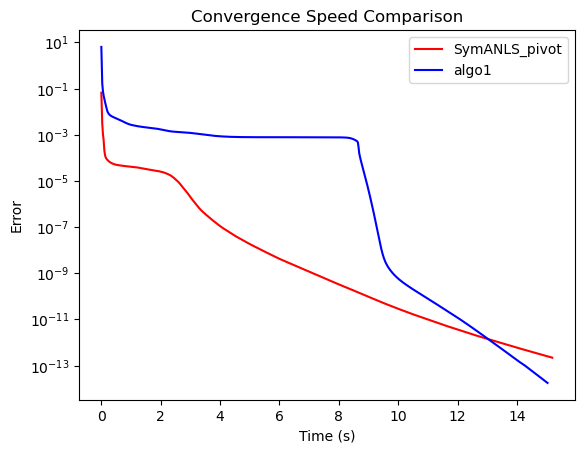

In [7]:
# y use log scale
plt.plot(t[:], e[:], c='r', label='SymANLS_pivot')
plt.plot(t_algo1[:], e_algo1[:], c='b', label='algo1')
plt.yscale('log')
plt.title('Convergence Speed Comparison')
plt.xlabel('Time (s)')
plt.ylabel('Error')
plt.legend()
plt.show()

In [ ]:
# y use log scale
# length = 1000
plt.plot(range(len(e)), e[:], c='r', label='SymANLS_pivot')
plt.plot(range(len(e_algo1)), e_algo1[:], c='b', label='algo1')
plt.yscale('log')
plt.legend()
plt.show()